
Исследование скорости обучения
Скорость = 0.001  MSE(train) = 0.0054218939
Скорость = 0.01   MSE(train) = 0.013408446
Скорость = 0.05   MSE(train) = inf
Скорость = 0.1    MSE(train) = inf
Скорость = 0.5    MSE(train) = inf
Скорость = 1      MSE(train) = inf


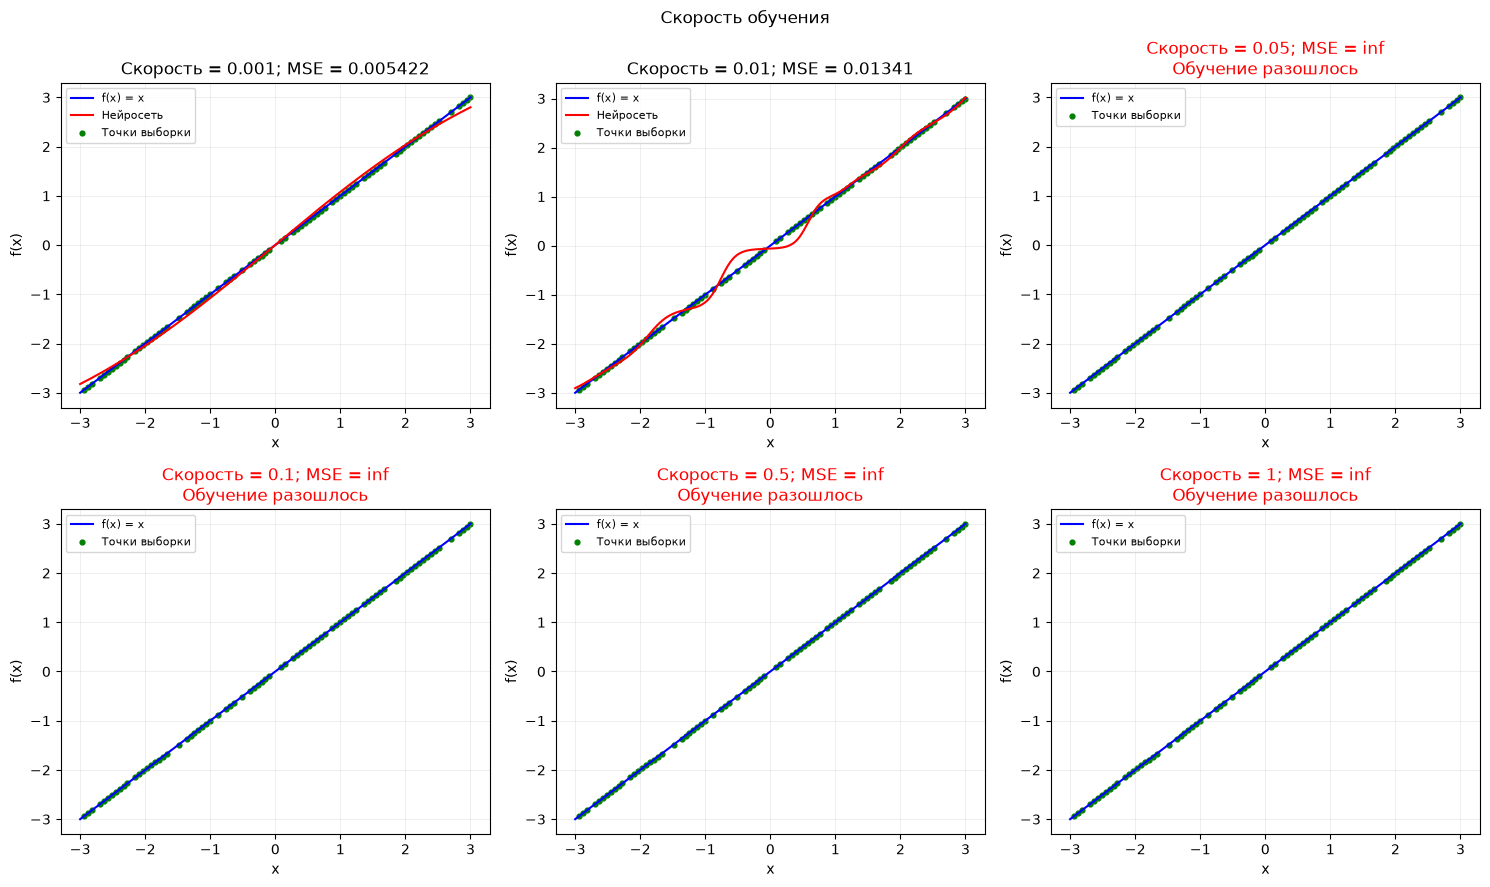

Лучшая скорость: 0.001; MSE(test) = 0.0063007453


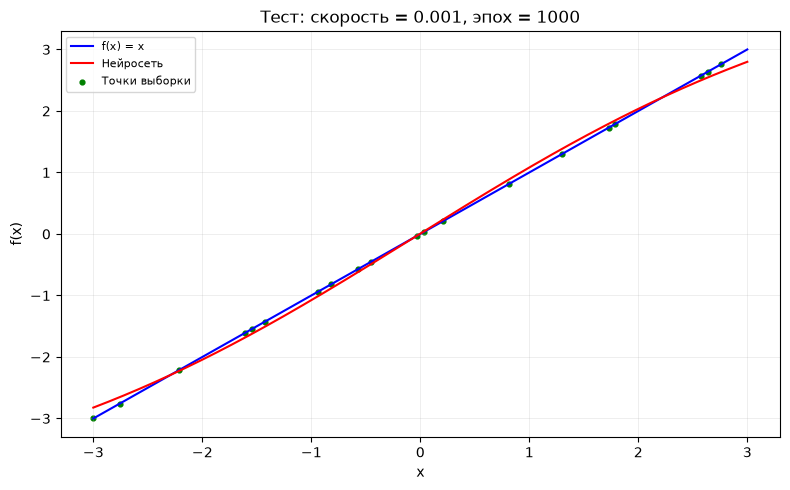


Исследование числа эпох
Эпохи = 20    MSE(train) = 0.38109271
Эпохи = 100   MSE(train) = 0.088948535
Эпохи = 500   MSE(train) = 0.032052964
Эпохи = 1000  MSE(train) = 0.013408446
Эпохи = 2000  MSE(train) = 0.0055412543
Эпохи = 5000  MSE(train) = 0.0026978752


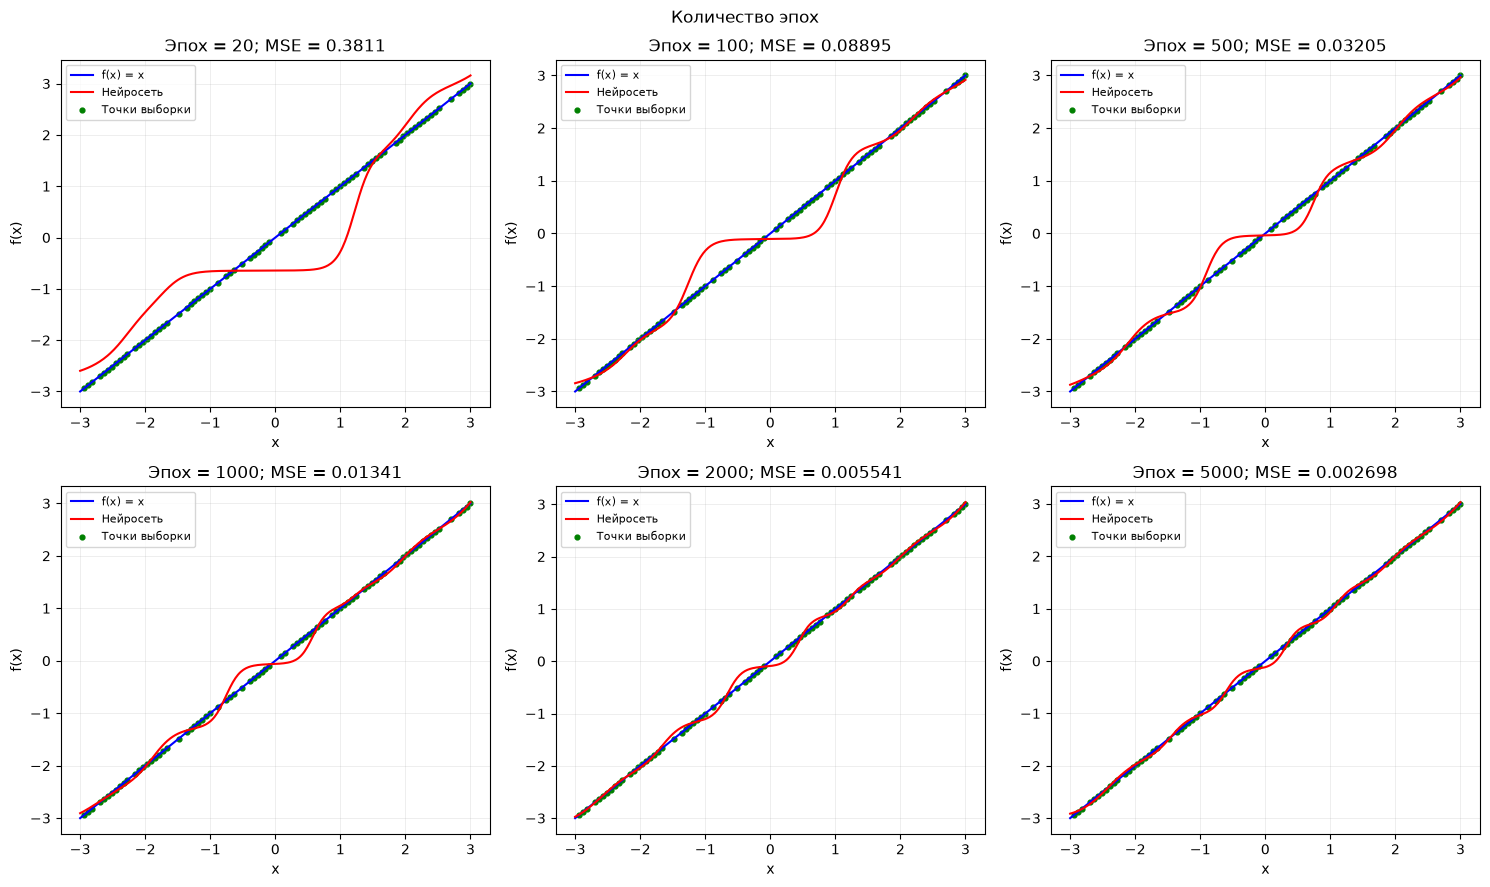

Лучшее число эпох: 5000; MSE(test) = 0.0052492594


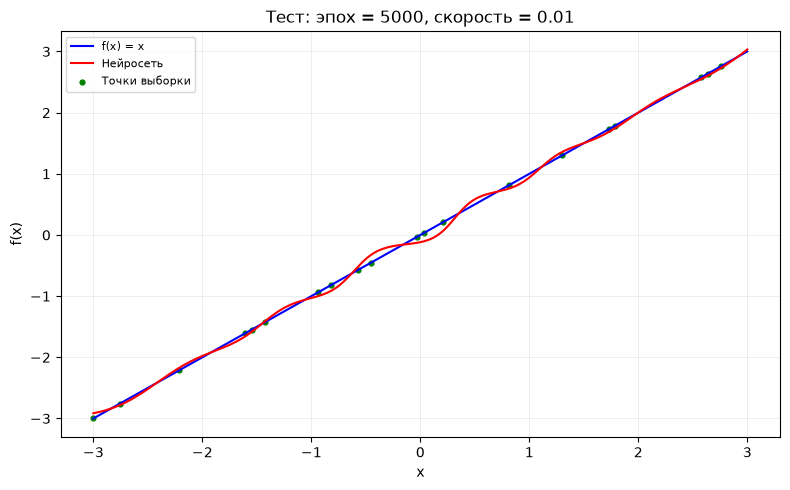

In [5]:
"""вариант 3: f(x) = x; 20 нейронов; x ∈ [-3, 3]"""
import numpy as np
import matplotlib.pyplot as plt
import copy


X_MIN = -3
X_MAX = 3
POINT_COUNT = 100
TRAIN_COUNT = 80
CURVE_POINT_COUNT = 300
HIDDEN_NEURONS = 20
DATA_RANDOM_SEED = 2026
WEIGHTS_RANDOM_SEED = 123
INITIAL_WEIGHT_MIN = -0.5
INITIAL_WEIGHT_MAX = 0.5
SIGMOID_CLIP = 500
MAX_WEIGHT_ABS = 1_000_000
MAX_MSE = 1_000_000_000_000
LEARNING_RATES = [0.001, 0.01, 0.05, 0.1, 0.5, 1]
EPOCH_COUNTS = [20, 100, 500, 1000, 2000, 5000]
BASE_RATE = 0.01
BASE_EPOCHS = 1000
PLOT_ROWS = 2
PLOT_COLUMNS = 3


def target_function(x):
    return x


def generate_data():
    x_all = np.linspace(X_MIN, X_MAX, POINT_COUNT)
    y_all = target_function(x_all)
    rng = np.random.default_rng(DATA_RANDOM_SEED)
    shuffled_indices = rng.permutation(POINT_COUNT)

    x_train, y_train = [], []
    x_test, y_test = [], []

    for position, point_index in enumerate(shuffled_indices):
        if position < TRAIN_COUNT:
            x_train.append(x_all[point_index])
            y_train.append(y_all[point_index])
        else:
            x_test.append(x_all[point_index])
            y_test.append(y_all[point_index])

    return (np.array(x_train), np.array(y_train),
            np.array(x_test), np.array(y_test))


def initialize_weights():
    rng = np.random.default_rng(WEIGHTS_RANDOM_SEED)
    return {
        "input": rng.uniform(INITIAL_WEIGHT_MIN, INITIAL_WEIGHT_MAX, HIDDEN_NEURONS),
        "hidden_bias": rng.uniform(INITIAL_WEIGHT_MIN, INITIAL_WEIGHT_MAX, HIDDEN_NEURONS),
        "output": rng.uniform(INITIAL_WEIGHT_MIN, INITIAL_WEIGHT_MAX, HIDDEN_NEURONS),
        "output_bias": 0,
    }

def sigmoid(z):
    z = np.clip(z, -SIGMOID_CLIP, SIGMOID_CLIP)
    return 1 / (1 + np.exp(-z))


def forward(x_values, weights):
    hidden_outputs = []
    predictions = np.full(
        len(x_values),
        weights["output_bias"],
        dtype=float)

    for neuron in range(HIDDEN_NEURONS):
        weighted_input = (weights["input"][neuron] * x_values
                          + weights["hidden_bias"][neuron])

        neuron_output = sigmoid(weighted_input)
        hidden_outputs.append(neuron_output)
        predictions += weights["output"][neuron] * neuron_output

    return predictions, hidden_outputs


def backward(x_values, y_values, predictions, hidden_outputs, weights):
    point_count = len(x_values)
    output_error_gradient = 2 * (predictions - y_values) / point_count
    #output_error_gradient = (predictions - y_values) - обучение будет медленее


    gradients = {
        "input": np.zeros(HIDDEN_NEURONS),
        "hidden_bias": np.zeros(HIDDEN_NEURONS),
        "output": np.zeros(HIDDEN_NEURONS),
        "output_bias": float(np.sum(output_error_gradient)),
    }

    for neuron in range(HIDDEN_NEURONS):
        neuron_output = hidden_outputs[neuron]
        gradients["output"][neuron] = np.sum(output_error_gradient * neuron_output)
        hidden_gradient = (output_error_gradient * weights["output"][neuron]
                           * neuron_output * (1 - neuron_output))

        gradients["input"][neuron] = np.sum(hidden_gradient * x_values)
        gradients["hidden_bias"][neuron] = np.sum(hidden_gradient)

    return gradients


def update_weights(weights, gradients, learning_rate):
    for name in weights:
        weights[name] -= learning_rate * gradients[name]


def calculate_mse(x_values, y_values, weights):
    predictions, hidden_outputs = forward(x_values, weights)
    return float(np.mean((predictions - y_values) ** 2))


def weights_are_valid(weights):
    for name in weights:
        values = np.asarray(weights[name])
        if not np.all(np.isfinite(values)):
            return False
        if np.any(np.abs(values) > MAX_WEIGHT_ABS):
            return False
    return True


def train_network(x_train, y_train, initial_weights, learning_rate, epochs):
    weights = copy.deepcopy(initial_weights)
    mse_history = []

    for epoch in range(epochs):
        predictions, hidden_outputs = forward(x_train, weights)
        current_mse = float(np.mean((predictions - y_train) ** 2))
        if not np.isfinite(current_mse) or current_mse > MAX_MSE:
            return None, mse_history

        gradients = backward(x_train, y_train, predictions, hidden_outputs, weights)
        update_weights(weights, gradients, learning_rate)
        if not weights_are_valid(weights):
            return None, mse_history

        updated_mse = calculate_mse(x_train, y_train, weights)
        if not np.isfinite(updated_mse) or updated_mse > MAX_MSE:
            return None, mse_history

        mse_history.append(updated_mse)

    return weights, mse_history


def draw_approximation(axis, weights, x_points, y_points, title):
    x_curve = np.linspace(X_MIN, X_MAX, CURVE_POINT_COUNT)
    axis.plot(x_curve, target_function(x_curve), color="blue", label="f(x) = x")
    if weights is None:
        axis.set_title(f"{title}\nОбучение разошлось", color="red")
    else:
        predictions, hidden_outputs = forward(x_curve, weights)
        axis.plot(x_curve, predictions, color="red", label="Нейросеть")
        axis.set_title(title)
    axis.scatter(x_points, y_points, color="green", s=12, label="Точки выборки")
    axis.set_xlabel("x")
    axis.set_ylabel("f(x)")
    axis.grid(alpha=0.3)
    axis.legend(fontsize=8)


def show_experiment_grid(results, x_train, y_train, title, parameter_label):
    figure, axes = plt.subplots(PLOT_ROWS, PLOT_COLUMNS, figsize=(15, 9))
    axes_list = axes.flatten()
    for axis, result in zip(axes_list, results):
        subtitle = f"{parameter_label} = {result["parameter"]}; MSE = {result["mse"]:.4g}"
        draw_approximation(axis, result["weights"], x_train, y_train, subtitle)

    figure.suptitle(title)
    figure.tight_layout()
    plt.show()


def show_test_plot(weights, x_test, y_test, title):
    figure, axis = plt.subplots(figsize=(8, 5))
    draw_approximation(axis, weights, x_test, y_test, title)
    figure.tight_layout()
    plt.show()


def choose_best_result(results):
    best_result = results[0]
    for result in results:
        if result["mse"] < best_result["mse"]:
            best_result = result

    return best_result


def run_rate_experiment(x_train, y_train, x_test, y_test, initial_weights):
    print("\nИсследование скорости обучения")
    results = []
    for learning_rate in LEARNING_RATES:
        weights, history = train_network(x_train, y_train, initial_weights,
                                         learning_rate, BASE_EPOCHS)
        train_mse = (calculate_mse(x_train, y_train, weights)
                     if weights is not None else float("inf"))

        results.append({"parameter": learning_rate, "mse": train_mse, "weights": weights})
        print(f"Скорость = {learning_rate:<6} MSE(train) = {train_mse:.8g}")

    show_experiment_grid(results, x_train, y_train, "Скорость обучения", "Скорость")
    best_result = choose_best_result(results)

    if best_result["weights"] is not None:
        test_mse = calculate_mse(x_test, y_test, best_result["weights"])
        print(f"Лучшая скорость: {best_result["parameter"]}; MSE(test) = {test_mse:.8g}")
        show_test_plot(best_result["weights"], x_test, y_test,
                       f"Тест: скорость = {best_result["parameter"]}, эпох = {BASE_EPOCHS}")

    return best_result["parameter"]


def run_epoch_experiment(x_train, y_train, x_test, y_test, initial_weights):
    print("\nИсследование числа эпох")
    results = []
    for epochs in EPOCH_COUNTS:
        weights, history = train_network(x_train, y_train, initial_weights,
                                         BASE_RATE, epochs)
        train_mse = (calculate_mse(x_train, y_train, weights)
                     if weights is not None else float("inf"))
        results.append({"parameter": epochs, "mse": train_mse, "weights": weights})
        print(f"Эпохи = {epochs:<5} MSE(train) = {train_mse:.8g}")

    show_experiment_grid(results, x_train, y_train, "Количество эпох", "Эпох")
    best_result = choose_best_result(results)

    if best_result["weights"] is not None:
        test_mse = calculate_mse(x_test, y_test, best_result["weights"])
        print(f"Лучшее число эпох: {best_result["parameter"]}; MSE(test) = {test_mse:.8g}")
        show_test_plot(best_result["weights"], x_test, y_test,
                       f"Тест: эпох = {best_result["parameter"]}, скорость = {BASE_RATE}")


    return best_result["parameter"]


def main():
    x_train, y_train, x_test, y_test = generate_data()
    initial_weights = initialize_weights()
    run_rate_experiment(x_train, y_train, x_test, y_test, initial_weights)
    run_epoch_experiment(x_train, y_train, x_test, y_test, initial_weights)


if __name__ == "__main__":
    main()
